# Module 3 (CO3): Baseline Classification Models (Logistic Regression, Decision Trees, KNN)
**Project**: Anti-Money Laundering Detection (IBM Benchmark)  
**Focus**: Baseline modeling, cost-sensitive reweighting, and dynamic confusion matrix visualization.

In [1]:
# 1. Load Dataset & Train Baseline Classifiers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

# Load benchmark data
df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour
df['dayofweek'] = df['Timestamp'].dt.dayofweek
df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype(int)
df['is_night'] = df['hour'].isin([0, 1, 2, 3, 4, 5, 22, 23]).astype(int)
df['is_cross_bank'] = (df['From Bank'] != df['To Bank']).astype(int)
df['amount_diff'] = np.abs(df['Amount Paid'] - df['Amount Received'])
df['log_amount_paid'] = np.log1p(df['Amount Paid'])
df['structuring_flag'] = ((df['Amount Paid'] >= 8500) & (df['Amount Paid'] < 10000)).astype(int)

format_dummies = pd.get_dummies(df['Payment Format'], prefix='format', drop_first=False).astype(int)
df = pd.concat([df, format_dummies], axis=1)

feature_cols = ['Amount Paid', 'Amount Received', 'amount_diff', 'log_amount_paid', 'is_cross_bank', 'structuring_flag', 'hour', 'dayofweek', 'is_weekend', 'is_night'] + format_dummies.columns.tolist()
X = df[feature_cols]
y = df['Is Laundering']

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Baselines
print("Training Logistic Regression...")
lr = LogisticRegression(class_weight='balanced', max_iter=200, random_state=42)
lr.fit(X_train_scaled, y_train)

print("Training Decision Tree...")
dt = DecisionTreeClassifier(max_depth=12, class_weight='balanced', random_state=42)
dt.fit(X_train, y_train)

print("Training K-Nearest Neighbors...")
knn_idx = np.random.choice(len(X_train_scaled), 15000, replace=False)
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_scaled[knn_idx], y_train.iloc[knn_idx])
print("Baselines trained successfully!")


Training Logistic Regression...


Training Decision Tree...


Training K-Nearest Neighbors...
Baselines trained successfully!


## 2. Dynamic Baseline Evaluation & Metrics

In [2]:
# Calculate predictions & live metrics
models = {'Logistic Regression': (lr, X_test_scaled), 'Decision Tree': (dt, X_test), 'K-Nearest Neighbors': (knn, X_test_scaled)}
results = []
preds_dict = {}

for name, (clf, X_eval) in models.items():
    y_pred = clf.predict(X_eval)
    y_prob = clf.predict_proba(X_eval)[:, 1]
    preds_dict[name] = y_pred
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

baseline_df = pd.DataFrame(results)
print("Baseline Evaluation Metrics (Calculated Live on 20,000 Holdout Test Records):")
display(baseline_df.round(4))


Baseline Evaluation Metrics (Calculated Live on 20,000 Holdout Test Records):


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8844,0.2914,0.8618,0.4355,0.9079
1,Decision Tree,0.9146,0.3561,0.8048,0.4938,0.8778
2,K-Nearest Neighbors,0.9510,0.5335,0.4155,0.4671,0.8646


## 3. Dynamic Visualizations: Confusion Matrices & Baseline Comparison

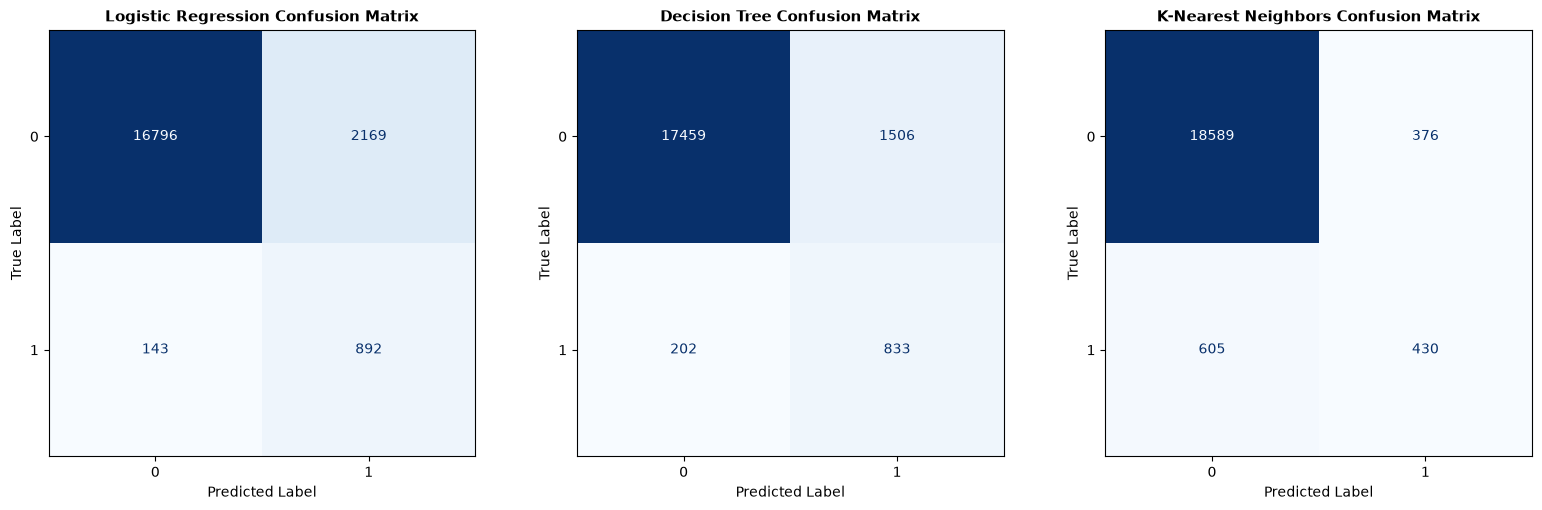

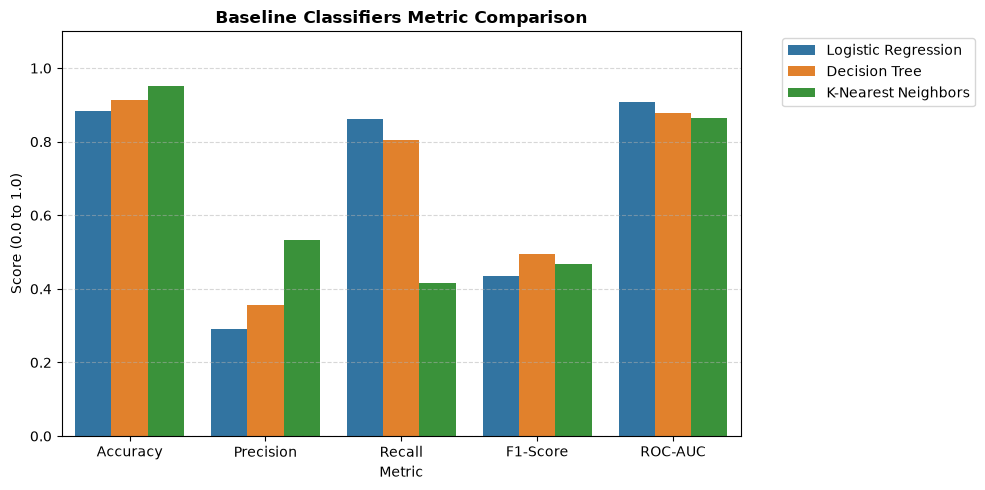

In [3]:
# Visualization: Dynamic Confusion Matrices for Baselines
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, (name, y_pred) in enumerate(preds_dict.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f'{name} Confusion Matrix', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

# Visualization: Model Comparison Bar Chart
metrics_melted = baseline_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_melted, x='Metric', y='Score', hue='Model', palette='tab10')
plt.title('Baseline Classifiers Metric Comparison', fontsize=12, fontweight='bold')
plt.ylim(0, 1.1)
plt.ylabel('Score (0.0 to 1.0)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
